<a href="https://colab.research.google.com/github/franciscorafael-dotcom/DL_P2_TP2_G2-F1/blob/main/notebooks/criar_classe_outro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classe "Outro": imagens que não são folhas de videira (P2 · Tema F)

O classificador só conhecia as 4 classes do FieldVitis, por isso uma foto de um cão ou de um peixe tinha sempre de "ser" uma doença. Esta classe ensina o modelo a dizer "isto não é uma folha de videira".

| Fonte | Imagens | O que contém | Licença (confirmar) |
|---|---|---|---|
| Hugging Face `AI-Lab-Makerere/beans` | 60 | folhas de feijão fotografadas no campo (negativos difíceis) | MIT |
| TFDS `tf_flowers` | 50 | flores | CC BY 2.0 |
| Hugging Face `timm/oxford-iiit-pet` | 50 | cães e gatos | CC BY-SA 4.0 |

Total: **160 imagens** (perto das 158 de Healthy e Leaf_blight). As folhas de outra planta são as mais importantes: sem elas o modelo aprenderia só "verde vs. não verde".

**Saídas:** `data/fieldvitis/Outro/*.jpg` (fora do git), `data/outro_fontes.csv` (no git: origem e licença de cada imagem) e `outro.zip` para partilhar com o grupo.

**Reprodutível:** ordem fixa das fontes + seed fixa. Correr **uma vez**; o grupo usa o mesmo `outro.zip`.

In [1]:
# 1. Caminhos (funciona no Google Colab e localmente)
import shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

try:
    import google.colab  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = Path("/content/DL_P2_TP2_G2-F1")
    if not REPO_DIR.exists():
        !git clone -q https://github.com/franciscorafael-dotcom/DL_P2_TP2_G2-F1.git {REPO_DIR}
else:
    cwd = Path.cwd().resolve()
    REPO_DIR = next((p for p in [cwd, *cwd.parents] if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
    if REPO_DIR is None:
        raise FileNotFoundError("Não foi possível encontrar a raiz do repositório.")

OUTRO_DIR = REPO_DIR / "data" / "fieldvitis" / "Outro"
FONTES_FILE = REPO_DIR / "data" / "outro_fontes.csv"
print("Repositório:", REPO_DIR)
print("Destino das imagens:", OUTRO_DIR)

Mounted at /content/drive
Repositório: /content/DL_P2_TP2_G2-F1
Destino das imagens: /content/DL_P2_TP2_G2-F1/data/fieldvitis/Outro


In [2]:
# 2. Composição da classe "Outro"
SEED_OUTRO = 2026   # seed fixa: a escolha das imagens é sempre a mesma
POOL = 1000         # escolhe-se ao acaso entre as primeiras 1000 imagens de cada fonte (ordem fixa)

FONTES = [
    # (origem, dataset, prefixo do ficheiro, n.º de imagens, o que contém, licença)
    ("huggingface", "AI-Lab-Makerere/beans", "feijao", 60, "folhas de feijão fotografadas no campo (negativos difíceis)", "MIT"),
    ("tfds",        "tf_flowers",            "flor",   50, "flores",                                                      "CC BY 2.0"),
    ("huggingface", "timm/oxford-iiit-pet",  "animal", 50, "cães e gatos",                                                "CC BY-SA 4.0"),
]
print("Total previsto:", sum(f[3] for f in FONTES), "imagens")

Total previsto: 160 imagens


In [3]:
# 3. Descarregar as fontes e guardar as imagens escolhidas (demora alguns minutos: ~0,8 GB no total)
# O dataset "beans" deixou de estar disponível no TFDS (erro 403); usa-se a cópia oficial no Hugging Face.
!pip install -q datasets importlib_resources
import tensorflow_datasets as tfds
from datasets import load_dataset

if OUTRO_DIR.exists():
    shutil.rmtree(OUTRO_DIR)          # recomeça do zero, para não misturar versões
OUTRO_DIR.mkdir(parents=True)

rng = np.random.RandomState(SEED_OUTRO)
registos = []
for origem, nome_ds, prefixo, n, descricao, licenca in FONTES:
    if origem == "huggingface":
        ds = load_dataset(nome_ds, split="train")
        n_pool = min(POOL, len(ds))
        escolhidos = sorted(rng.choice(n_pool, size=n, replace=False).tolist())
        imagens = ((i, ds[i]["image"]) for i in escolhidos)
    else:
        ds = tfds.load(nome_ds, split="train", shuffle_files=False)
        n_pool = min(POOL, int(ds.cardinality()))
        escolhidos = set(rng.choice(n_pool, size=n, replace=False).tolist())
        imagens = ((i, Image.fromarray(ex["image"]))
                   for i, ex in enumerate(tfds.as_numpy(ds.take(n_pool))) if i in escolhidos)

    for i, img in imagens:
        nome = f"{prefixo}_{i:05d}.jpg"
        img.convert("RGB").save(OUTRO_DIR / nome, quality=95)
        registos.append(dict(path=f"Outro/{nome}", fonte=nome_ds, indice=i,
                             descricao=descricao, licenca=licenca))
    print(f"{nome_ds}: {n} imagens guardadas")

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

... (15 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3680 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3669 [00:00<?, ? examples/s]

timm/oxford-iiit-pet: 50 imagens guardadas


In [4]:
# 4. Registo das fontes (este CSV vai para o git) e verificação
fontes = pd.DataFrame(registos).sort_values("path").reset_index(drop=True)
fontes.to_csv(FONTES_FILE, index=False)

ficheiros = sorted(OUTRO_DIR.glob("*.jpg"))
assert len(ficheiros) == len(fontes) == sum(f[3] for f in FONTES), "o n.º de imagens não bate certo"
print("Imagens na pasta Outro:", len(ficheiros))
display(fontes.groupby(["fonte", "licenca"]).size().rename("imagens").to_frame())

Imagens na pasta Outro: 160


,,imagens
fonte,licenca,
AI-Lab-Makerere/beans,MIT,60
tf_flowers,CC BY 2.0,50
timm/oxford-iiit-pet,CC BY-SA 4.0,50


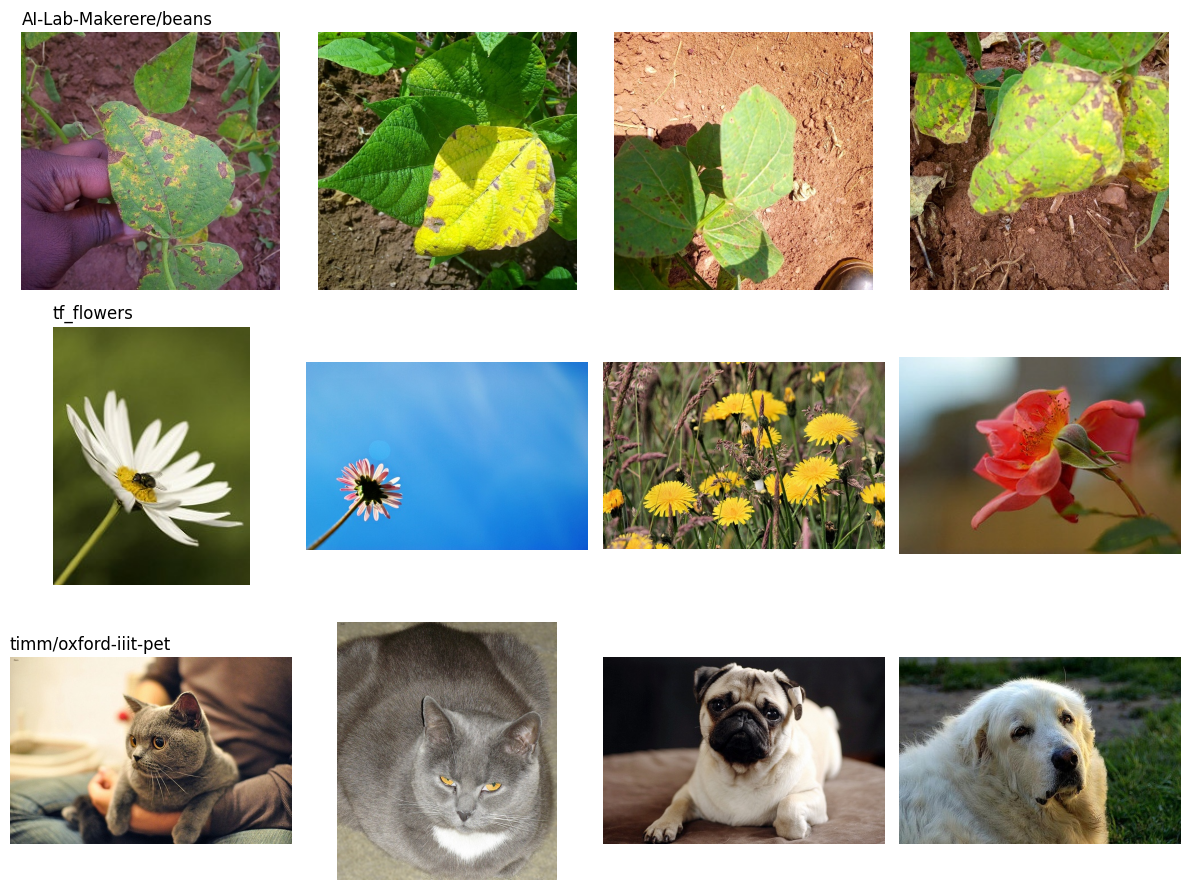

In [5]:
# 5. Inspeção visual: 4 imagens de cada fonte
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for linha, (_, nome_ds, *_ ) in enumerate(FONTES):
    amostra = fontes[fontes.fonte == nome_ds].head(4)
    for col, (_, r) in enumerate(amostra.iterrows()):
        ax = axes[linha, col]
        ax.imshow(Image.open(REPO_DIR / "data" / "fieldvitis" / r.path)); ax.axis("off")
        if col == 0: ax.set_title(nome_ds, loc="left")
plt.tight_layout(); plt.show()

In [6]:
# 6. Zip para partilhar com o grupo (Colab: vai para o Drive; local: fica em data/, que está fora do git)
destino = Path("/content/drive/MyDrive/outro") if EM_COLAB else REPO_DIR / "data" / "outro"
zip_path = shutil.make_archive(str(destino), "zip", root_dir=OUTRO_DIR.parent, base_dir="Outro")
print("Zip criado:", zip_path)
print("Quem o usar descomprime-o dentro de data/fieldvitis/ (fica data/fieldvitis/Outro/...)")

Zip criado: /content/drive/MyDrive/outro.zip
Quem o usar descomprime-o dentro de data/fieldvitis/ (fica data/fieldvitis/Outro/...)
